# 第185章: ProGAN と StyleGAN — 部品を1つずつ足して、壊れた場所を測る

## Mapping Network・AdaIN・スタイル混合・段階的成長

---

### このノートブックの位置づけ

181 では DCGAN の経験則を**1つずつ外して**測りました。本章は逆向きです。
**動いている DCGAN に StyleGAN の部品を1つずつ足します。**

最初に正直に書きます。**本章の主要な実験は、ほとんど失敗します。**
8つの仮説を立てて5つが棄却されました。それでも章として成立するのは、
**なぜ失敗するのかを測ると、原典の「細かい実装の工夫」が何のためにあるのかが分かる**からです。

| 章 | 関係 |
|---|---|
| **181** | 経験則を外す / 本章は足す。評価指標の作り方（分類器を特徴抽出器にする）を引き継ぐ |
| **182** | 占有率・ばらつきで判断する規律 |
| **184** | 「損失が見ない自由度は任意になる」。本章で生成モデル版が出てくる |
| **305-308** | GAN の潜在空間の編集（Z 空間と W 空間、属性方向）。**本章はそこが前提にしている主張を測る** |

### 本章で確かめること

1. 素の DCGAN に Mapping Network を足すと何が起きるか
2. 壊れる原因はどこか（8つの仮説を順に潰す）
3. 動く形を見つける — 残差写像
4. **W 空間は Z 空間より「ほどけている」か**（305 章の主張を測る）
5. **スタイル混合は層ごとに別の性質を制御するか**（StyleGAN の主張を測る）
6. 解像度カリキュラム（段階的成長の簡略版）は効くか

### 前提

- **181**（DCGAN と画像の評価指標）、**182**（モード崩壊の指標）、**184**（条件付けと指標の罠）
- BatchNorm / InstanceNorm（**113**）

> ⏱ **実行時間の注意**: 本章は分類器1つと **19 回の GAN 学習**を行います。
> CPU で合計 **35〜50分**です。最初に通して実行してから読むことをお勧めします。

## 目次

1. [環境セットアップ](#setup)
2. [2つの因子が測れるデータを作る](#data)
3. [部品を1つずつ足す — Mapping Network で壊れる](#build)
4. [原因を順に潰す](#diagnose)
5. [動く形を見つける — 残差写像](#residual)
6. [W 空間は Z 空間よりほどけているか](#probe)
7. [スタイル混合は層ごとに何を制御するか](#mixing)
8. [解像度カリキュラム（段階的成長の簡略版）](#progressive)
9. [実装でつまずいた点](#pitfalls)
10. [まとめとチートシート](#summary)
11. [自己評価クイズ](#quiz)

<a id="setup"></a>
## 1. 環境セットアップ

In [1]:
# ============================================================
# 環境セットアップ
# ============================================================

import math
import os
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy.linalg import sqrtm
from torchvision import datasets

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)

plt.rcParams["figure.figsize"] = (12, 4.5)
plt.rcParams["font.size"] = 10
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

print("torch:", torch.__version__)

torch: 2.9.1


<a id="data"></a>
## 2. 2つの因子が測れるデータを作る

StyleGAN の主張は「粗い層が**形**を、細かい層が**見た目**を決める」です。
これを測るには、**形と見た目が独立に決まり、どちらも生成画像から読み取れる**データが要ります。

カラー MNIST を作ります。

| 因子 | 実体 | 生成画像からの読み取り方 |
|---|---|---|
| **形** | 数字（10クラス） | グレースケール化した分類器で判定 |
| **見た目** | 色相（8種類） | 前景画素の平均 RGB を基準色と照合 |

色相の推定は学習を使わないので誤差が入りません（後で一致率を確認します）。
解像度は 16x16 にします（181 第2節の理由: ストライド 2 の全層で $k$ が $s$ の倍数になる）。

In [2]:
# ============================================================
# カラー MNIST 16x16（数字 x 色相）
# ============================================================

candidates = ["data", "notebooks/generative/data", "../generative/data",
              os.path.join(os.getcwd(), "data")]
data_root = None
for c in candidates:
    if os.path.isdir(os.path.join(c, "MNIST")):
        data_root = c
        break
if data_root is None:
    raise FileNotFoundError(f"MNIST が見つかりません。探した場所: {candidates}")
print("MNIST の場所:", data_root)

N_HUE = 8
HUES = torch.tensor([[1.0, 0.2, 0.2], [1.0, 0.6, 0.1], [0.9, 0.9, 0.1], [0.2, 0.9, 0.2],
                     [0.1, 0.8, 0.8], [0.2, 0.4, 1.0], [0.6, 0.2, 0.9], [1.0, 0.3, 0.7]])


def make_colored(d, seed=0):
    g = torch.Generator().manual_seed(seed)
    X = (d.data.float() / 255.0)[:, None]
    X = F.avg_pool2d(F.pad(X, (2, 2, 2, 2)), 2)        # 28 -> 32 -> 16
    h = torch.randint(0, N_HUE, (len(X),), generator=g)
    rgb = X * HUES[h][:, :, None, None]                # 前景に色を乗せる
    return rgb * 2 - 1, d.targets, h                   # [-1, 1]（tanh 用）


X_train, Y_train, H_train = make_colored(
    datasets.MNIST(root=data_root, train=True, download=False), seed=0)
X_test, Y_test, H_test = make_colored(
    datasets.MNIST(root=data_root, train=False, download=False), seed=1)
# 参照データは必ず無作為化する（181 第3節のつまずき）
_p = torch.randperm(len(X_test), generator=torch.Generator().manual_seed(7))
X_test, Y_test, H_test = X_test[_p], Y_test[_p], H_test[_p]

print(f"学習 {tuple(X_train.shape)}  テスト {tuple(X_test.shape)}  "
      f"範囲 [{float(X_train.min()):.1f}, {float(X_train.max()):.1f}]")

MNIST の場所: notebooks/generative/data
学習 (60000, 3, 16, 16)  テスト (10000, 3, 16, 16)  範囲 [-1.0, 1.0]


In [3]:
# ============================================================
# 評価器: 数字の分類器（グレースケール入力）と色相の推定器
# ============================================================

def to_gray(x):
    return x.mean(1, keepdim=True)


class DigitClf(nn.Module):
    # 入力をグレースケールにするので、色相に依存しない
    def __init__(self, ch=32):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(1, ch, 3, 2, 1), nn.ReLU(),
            nn.Conv2d(ch, ch * 2, 3, 2, 1), nn.ReLU(),
            nn.Flatten(), nn.Linear(ch * 2 * 16, 64), nn.ReLU())
        self.head = nn.Linear(64, 10)

    def feat(self, x):
        return self.body(to_gray(x))

    def forward(self, x):
        return self.head(self.feat(x))


def train_digit_clf(steps=1500, seed=0, batch=256):
    torch.manual_seed(seed)
    C = DigitClf()
    opt = torch.optim.Adam(C.parameters(), lr=1e-3)
    for _ in range(steps):
        j = torch.randint(0, len(X_train), (batch,))
        opt.zero_grad()
        F.cross_entropy(C(X_train[j]), Y_train[j]).backward()
        opt.step()
    C.eval()
    return C


@torch.no_grad()
def est_hue(x):
    # 前景（明るい画素）の平均 RGB を正規化し、最も近い基準色の番号を返す。学習は不要
    v = (x + 1) / 2
    w = v.mean(1, keepdim=True)
    m = (w > w.flatten(1).max(1).values[:, None, None, None] * 0.5).float()
    s = (v * m).flatten(2).sum(-1) / m.flatten(2).sum(-1).clamp(min=1e-6)
    s = s / s.norm(dim=-1, keepdim=True).clamp(min=1e-6)
    ref = HUES / HUES.norm(dim=-1, keepdim=True)
    return (s[:, None, :] * ref[None]).sum(-1).argmax(-1)


t0 = time.time()
CLF = train_digit_clf()
with torch.no_grad():
    acc = (torch.cat([CLF(X_test[i:i + 2000]).argmax(1)
                      for i in range(0, len(X_test), 2000)]) == Y_test).float().mean()
hue_acc = (est_hue(X_test[:5000]) == H_test[:5000]).float().mean()
print(f"数字の分類器: テスト精度 {float(acc):.4f}   学習 {time.time() - t0:.0f}s")
print(f"色相の推定器: 真のラベルとの一致率 {float(hue_acc):.4f}")

数字の分類器: テスト精度 0.9729   学習 39s
色相の推定器: 真のラベルとの一致率 1.0000


In [4]:
# ============================================================
# 指標（181 と同じ作り。FID は分類器の特徴空間で測る）
# ============================================================

@torch.no_grad()
def features(X, bs=2000):
    return torch.cat([CLF.feat(X[i:i + bs]) for i in range(0, len(X), bs)])


@torch.no_grad()
def class_logits(X, bs=2000):
    return torch.cat([CLF(X[i:i + bs]) for i in range(0, len(X), bs)])


REF_FEAT = features(X_test[:5000])
LIVE = REF_FEAT.std(0) > 1e-8          # 死んだ ReLU 次元を落とす（181 のつまずき 2）


def fid_feature(A, B=None):
    B = REF_FEAT if B is None else B
    A = A[:, LIVE].numpy().astype(np.float64)
    B = B[:, LIVE].numpy().astype(np.float64)
    m1, m2 = A.mean(0), B.mean(0)
    C1, C2 = np.cov(A, rowvar=False), np.cov(B, rowvar=False)
    cc = sqrtm(C1 @ C2)
    if np.iscomplexobj(cc):
        cc = cc.real
    return float(((m1 - m2) ** 2).sum() + np.trace(C1 + C2 - 2 * cc))


def checkerboard(X):
    g = [X[:, :, i::2, j::2].mean() for i in range(2) for j in range(2)]
    return float(torch.stack(g).std() / X.std())


def image_metrics(S):
    p = class_logits(S).softmax(-1)
    occ = torch.bincount(p.argmax(-1), minlength=10).float() / len(S)
    h = est_hue(S)
    hocc = torch.bincount(h, minlength=N_HUE).float() / len(S)
    return dict(fid=fid_feature(features(S)),
                dig_dev=float((occ - 0.1).abs().max()),
                hue_dev=float((hocc - 1.0 / N_HUE).abs().max()),
                conf=float(p.max(-1).values.mean()),
                chk=checkerboard(S))


def eff_dim(X):
    # 共分散の固有値の participation ratio = 「実質いくつの次元を使っているか」
    ev = np.linalg.eigvalsh(np.cov(X.numpy().astype(np.float64), rowvar=False))
    ev = np.clip(ev, 0, None)
    return float((ev.sum() ** 2) / (ev ** 2).sum())


print("基準（真のデータ）")
print(f"{'データ':<22}{'FID':>9}{'数字の偏り':>11}{'色相の偏り':>11}{'確信度':>9}{'市松':>10}")
print("-" * 72)
base = {}
for tag, S in [("test[5000:10000]", X_test[5000:10000]), ("train[:5000]", X_train[:5000])]:
    m = image_metrics(S)
    base[tag] = m
    print(f"{tag:<22}{m['fid']:9.4f}{m['dig_dev']:11.4f}{m['hue_dev']:11.4f}"
          f"{m['conf']:9.4f}{m['chk']:10.5f}")
print("-" * 72)
Z_EFF = eff_dim(torch.randn(4000, 32, generator=torch.Generator().manual_seed(0)))
print(f"参考: 32 次元の標準正規の有効次元 {Z_EFF:.2f}（名目 32）")

基準（真のデータ）
データ                         FID      数字の偏り      色相の偏り      確信度        市松
------------------------------------------------------------------------


test[5000:10000]         0.6026     0.0192     0.0102   0.9714   0.00208


train[:5000]             1.3508     0.0126     0.0124   0.9727   0.00151
------------------------------------------------------------------------
参考: 32 次元の標準正規の有効次元 31.72（名目 32）


<a id="build"></a>
## 3. 部品を1つずつ足す — Mapping Network で壊れる

StyleGAN と素の DCGAN の違いは3つです。

| 部品 | 素の DCGAN | StyleGAN |
|---|---|---|
| 潜在の扱い | $z \sim \mathcal{N}(0,I)$ を直接入力 | $z \to$ **Mapping Network** $\to w$ |
| 正規化 | BatchNorm | **AdaIN**（$w$ で変調） |
| 細部の多様性 | $z$ のみ | **各層にノイズを足す** |

骨格（転置畳み込みで 1→4→8→16）は変えずに、この3つを順に足します。
判別器は 181 の結果に従って MaxPool で縮めます。

$$\mathrm{AdaIN}(x, w) = \big(1 + \gamma(w)\big)\,\frac{x - \mu(x)}{\sigma(x)} + \beta(w)$$

$\mu, \sigma$ は**各サンプル・各チャネルごと**の空間平均と標準偏差（instance norm）です。
BatchNorm がバッチ方向で統計を取るのに対し、AdaIN はサンプルごとに取るのが違いです。

In [5]:
# ============================================================
# 生成器・判別器（部品を切り替えられるようにする）
# ============================================================

NZ = NW = 32


class PixelNorm(nn.Module):
    def forward(self, x):
        return x / (x.pow(2).mean(-1, keepdim=True) + 1e-8).sqrt()


class Mapping(nn.Module):
    # 素朴な実装: Linear + LeakyReLU を重ねるだけ
    def __init__(self, nz=NZ, nw=NW, depth=4, hidden=64, pixnorm=True):
        super().__init__()
        L = [PixelNorm()] if pixnorm else []
        d = nz
        for _ in range(depth):
            L += [nn.Linear(d, hidden), nn.LeakyReLU(0.2)]
            d = hidden
        L += [nn.Linear(d, nw)]
        self.net = nn.Sequential(*L)

    def forward(self, z):
        return self.net(z)


class AdaIN(nn.Module):
    def __init__(self, ch, nw=NW):
        super().__init__()
        self.aff = nn.Linear(nw, ch * 2)
        self.ch = ch

    def forward(self, x, w):
        a = self.aff(w)
        g, b = a[:, :self.ch, None, None], a[:, self.ch:, None, None]
        return F.instance_norm(x) * (1 + g) + b


class Gen(nn.Module):
    # 骨格は DCGAN のまま。norm='bn' で BatchNorm、'adain' で AdaIN
    def __init__(self, ch=48, norm="bn", noise=False, nin=NZ):
        super().__init__()
        self.norm, self.noise, self.ch = norm, noise, ch
        self.d1 = nn.ConvTranspose2d(nin, ch * 4, 4, 1, 0, bias=False)   # 4x4
        self.d2 = nn.ConvTranspose2d(ch * 4, ch * 2, 4, 2, 1, bias=False)  # 8x8
        self.d3 = nn.ConvTranspose2d(ch * 2, 3, 4, 2, 1, bias=False)     # 16x16
        if norm == "bn":
            self.n1, self.n2 = nn.BatchNorm2d(ch * 4), nn.BatchNorm2d(ch * 2)
        else:
            self.a1, self.a2 = AdaIN(ch * 4), AdaIN(ch * 2)
        self.s1 = nn.Parameter(torch.zeros(1, ch * 4, 1, 1))
        self.s2 = nn.Parameter(torch.zeros(1, ch * 2, 1, 1))

    def forward(self, inp, ws=None):
        x = self.d1(inp)
        if self.noise:
            x = x + self.s1 * torch.randn(x.shape[0], 1, 4, 4)
        x = self.n1(x) if self.norm == "bn" else self.a1(x, ws[0])
        x = F.relu(x)
        x = self.d2(x)
        if self.noise:
            x = x + self.s2 * torch.randn(x.shape[0], 1, 8, 8)
        x = self.n2(x) if self.norm == "bn" else self.a2(x, ws[1])
        x = F.relu(x)
        return torch.tanh(self.d3(x))


class Disc(nn.Module):
    # 181 の結果に従い MaxPool で縮める
    def __init__(self, ch=48):
        super().__init__()
        self.net = nn.Sequential(
            nn.Sequential(nn.Conv2d(3, ch, 3, 1, 1, bias=False), nn.MaxPool2d(2)),
            nn.LeakyReLU(0.2),
            nn.Sequential(nn.Conv2d(ch, ch * 2, 3, 1, 1, bias=False), nn.MaxPool2d(2)),
            nn.BatchNorm2d(ch * 2), nn.LeakyReLU(0.2),
            nn.Conv2d(ch * 2, 1, 4, 1, 0, bias=False))

    def forward(self, x):
        return self.net(x).flatten(1).squeeze(-1)


bce = nn.BCEWithLogitsLoss()


def latents(M, n, gen=None, n_layers=2, use_map=True):
    z = torch.randn(n, NZ, generator=gen)
    w = M(z) if use_map else z
    return w[:, :, None, None], [w] * n_layers, z, w


def train_gan(steps=1000, seed=0, batch=128, lr=2e-4, map_lr_mult=1.0,
              map_cls=Mapping, use_map=True, norm="bn", noise=False, ch=48,
              track_every=0):
    torch.manual_seed(seed)
    M = map_cls() if use_map else None
    G = Gen(ch=ch, norm=norm, noise=noise, nin=(NW if use_map else NZ))
    D = Disc(ch=ch)
    groups = [{"params": list(G.parameters()), "lr": lr}]
    if use_map:
        groups.append({"params": list(M.parameters()), "lr": lr * map_lr_mult})
    og = torch.optim.Adam(groups, lr=lr, betas=(0.5, 0.999))
    od = torch.optim.Adam(D.parameters(), lr=lr, betas=(0.5, 0.999))
    hist = []
    z_fix = torch.randn(2000, NZ, generator=torch.Generator().manual_seed(5))

    def rec(it):
        if not use_map:
            return
        with torch.no_grad():
            w = M(z_fix)
        hist.append((it, float(w.std()), eff_dim(w)))

    if track_every:
        rec(0)
    for it in range(steps):
        xr = X_train[torch.randint(0, len(X_train), (batch,))]
        with torch.no_grad():
            inp, ws, _, _ = latents(M, batch, use_map=use_map)
            xf = G(inp, ws)
        od.zero_grad()
        (bce(D(xr), torch.ones(batch)) + bce(D(xf), torch.zeros(batch))).backward()
        od.step()
        inp, ws, _, _ = latents(M, batch, use_map=use_map)
        og.zero_grad()
        bce(D(G(inp, ws)), torch.ones(batch)).backward()
        og.step()
        if track_every and (it + 1) % track_every == 0:
            rec(it + 1)
    return M, G, D, hist


@torch.no_grad()
def sample_gan(M, G, n=5000, seed=1234, batch=500, use_map=True):
    g = torch.Generator().manual_seed(seed)
    was = G.training
    G.eval()
    O, Z, W = [], [], []
    for i in range(0, n, batch):
        b = min(batch, n - i)
        inp, ws, z, w = latents(M, b, gen=g, use_map=use_map)
        O.append(G(inp, ws))
        Z.append(z)
        W.append(w)
    G.train(was)
    return torch.cat(O), torch.cat(Z), torch.cat(W)

print("定義完了")

定義完了


In [6]:
# ============================================================
# 部品を1つずつ足す（4構成 x 2シード）
# ============================================================

BUILD = [
    ("0 素の DCGAN（z 入力・BatchNorm）", dict(use_map=False, norm="bn")),
    ("1 + Mapping Network（w 入力）", dict(use_map=True, norm="bn")),
    ("2 + AdaIN（BatchNorm を置換）", dict(use_map=True, norm="adain")),
    ("3 + 各層ノイズ", dict(use_map=True, norm="adain", noise=True)),
]

t0 = time.time()
build_res, build_G = {}, {}
print(f"{'構成':<40}{'FID':>10}{'シードごと':>18}{'数字の偏り':>11}{'色相の偏り':>11}")
print("-" * 90)
for tag, kw in BUILD:
    ms = []
    for s in [0, 1]:
        M, G, D, _ = train_gan(steps=1000, seed=s, **kw)
        S, _, _ = sample_gan(M, G, use_map=kw.get("use_map", True))
        if s == 0:
            build_G[tag] = (M, G, kw.get("use_map", True))
        ms.append(image_metrics(S))
    build_res[tag] = ms
    f = lambda k: np.array([m[k] for m in ms])
    print(f"{tag:<40}{f('fid').mean():10.3f}{str(np.round(f('fid'), 1).tolist()):>18}"
          f"{f('dig_dev').mean():11.4f}{f('hue_dev').mean():11.4f}")
print("-" * 90)
print(f"2シードの平均。経過 {time.time() - t0:.0f}s")
print(f"基準（真のデータ）: FID {base['test[5000:10000]']['fid']:.2f}  "
      f"数字の偏り {base['test[5000:10000]']['dig_dev']:.4f}")
# 失敗の基準として一様ノイズ画像も測る
_g = torch.Generator().manual_seed(0)
print(f"失敗の基準（一様ノイズ画像）: FID "
      f"{image_metrics(torch.rand(5000, 3, 16, 16, generator=_g) * 2 - 1)['fid']:.1f}")

構成                                             FID             シードごと      数字の偏り      色相の偏り
------------------------------------------------------------------------------------------


0 素の DCGAN（z 入力・BatchNorm）                  22.425      [26.1, 18.7]     0.0475     0.0672


/var/folders/6s/q776k1nj6rn9vjn979kn090w0000gn/T/ipykernel_54288/609723223.py:25: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  cc = sqrtm(C1 @ C2)


1 + Mapping Network（w 入力）                  643.175    [662.4, 623.9]     0.9000     0.8750


2 + AdaIN（BatchNorm を置換）                   608.779    [578.6, 638.9]     0.9000     0.7144


3 + 各層ノイズ                                  704.681    [806.1, 603.3]     0.9000     0.8750
------------------------------------------------------------------------------------------
2シードの平均。経過 907s
基準（真のデータ）: FID 0.60  数字の偏り 0.0192


失敗の基準（一様ノイズ画像）: FID 613.7


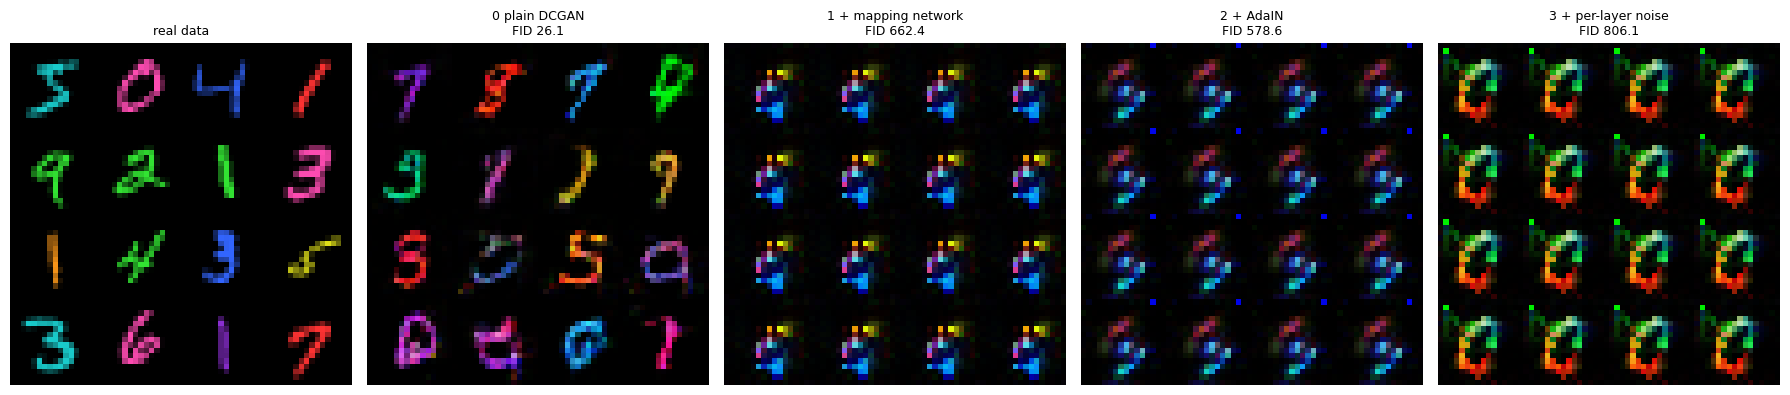

In [7]:
# ============================================================
# 図: 部品を足すと生成画像はどうなるか
# ============================================================

def show_grid(ax, S, title):
    g = S[:16].reshape(4, 4, 3, 16, 16).permute(0, 3, 1, 4, 2).reshape(64, 64, 3)
    ax.imshow(((g + 1) / 2).clamp(0, 1).numpy())
    ax.set_title(title, fontsize=9)
    ax.axis("off")


names_en = {"0 素の DCGAN（z 入力・BatchNorm）": "0 plain DCGAN",
            "1 + Mapping Network（w 入力）": "1 + mapping network",
            "2 + AdaIN（BatchNorm を置換）": "2 + AdaIN",
            "3 + 各層ノイズ": "3 + per-layer noise"}

fig, axes = plt.subplots(1, 5, figsize=(18, 3.9))
show_grid(axes[0], X_train[:16], "real data")
for ax, (tag, _) in zip(axes[1:], BUILD):
    M, G, um = build_G[tag]
    S, _, _ = sample_gan(M, G, n=16, use_map=um)
    show_grid(ax, S, f"{names_en[tag]}\nFID {build_res[tag][0]['fid']:.1f}")
plt.tight_layout()
plt.show()

### 読み取れること

| 構成 | FID | シードごと | 数字の偏り | 色相の偏り |
|---|---|---|---|---|
| 0 素の DCGAN（z 入力・BatchNorm） | **22.425** | 26.1 / 18.7 | 0.0475 | 0.0672 |
| **1 + Mapping Network** | **643.175** | 662.4 / 623.9 | **0.9000** | 0.8750 |
| 2 + AdaIN | 608.779 | 578.6 / 638.9 | 0.9000 | 0.7144 |
| 3 + 各層ノイズ | 704.681 | 806.1 / 603.3 | 0.9000 | 0.8750 |
| 基準（真のデータ） | 0.60 | — | 0.0192 | 0.0102 |
| **失敗の基準（一様ノイズ画像）** | **613.7** | — | — | — |

#### 壊れたのは Mapping Network を足した時点

素の DCGAN は FID 22.4 で動きます。そこに **Mapping Network を足しただけ**で 643.2。
**BatchNorm も入力の作り方も、判別器も、学習率も変えていません。**

しかも 643.2 は**一様ノイズ画像の 613.7 と同程度**です。
「少し悪くなった」ではなく**崩壊**しています。
数字の偏りが 0.9000 なのは、生成物がすべて1クラスに判定されているということです。

#### AdaIN とノイズは原因ではない

2 の AdaIN（608.8）は 1（643.2）とシードの範囲が重なります
（578.6-638.9 対 623.9-662.4）。つまり**差を読めません**。
3 のノイズも同じです。StyleGAN の目玉である AdaIN を疑いたくなりますが、
**その前の段で既に壊れています**。

> 部品を1つずつ足す順番が効きました。まとめて実装していたら
> 「AdaIN が悪いのか Mapping が悪いのか」を切り分けられませんでした。

<a id="diagnose"></a>
## 4. 原因を順に潰す

Mapping Network を足しただけで壊れました。**BatchNorm も入力の作り方も変えていません。**
原因を順に潰します。

### 仮説1: 初期化で信号が消えている

深い MLP を通すと信号の尺度が変わります。**学習ゼロで測れます。**

In [8]:
# ============================================================
# 仮説1: 学習ゼロで w の尺度と有効次元を測る
# ============================================================

z_probe = torch.randn(4000, NZ, generator=torch.Generator().manual_seed(0))
print(f"z の標準偏差 {float(z_probe.std()):.4f}  有効次元 {eff_dim(z_probe):.2f}（名目 {NZ}）")
print()
print("素朴な Mapping Network を通した w（学習ゼロ）")
print(f"{'depth':>6}{'PixelNorm':>11}{'w の std':>11}{'z 比':>8}{'有効次元':>10}")
print("-" * 46)
init_rows = []
for pn in [True, False]:
    for d in [1, 2, 4, 8]:
        torch.manual_seed(0)
        M = Mapping(depth=d, pixnorm=pn)
        with torch.no_grad():
            w = M(z_probe)
        init_rows.append((d, pn, float(w.std()), eff_dim(w)))
        print(f"{d:>6}{str(pn):>11}{float(w.std()):11.5f}"
              f"{float(w.std()) / float(z_probe.std()):8.4f}{eff_dim(w):10.2f}")
print("-" * 46)

z の標準偏差 1.0010  有効次元 31.72（名目 32）

素朴な Mapping Network を通した w（学習ゼロ）
 depth  PixelNorm    w の std     z 比      有効次元
----------------------------------------------
     1       True    0.24321  0.2430     13.83
     2       True    0.11251  0.1124     13.46
     4       True    0.08189  0.0818      7.35
     8       True    0.07766  0.0776      4.05
     1      False    0.24327  0.2430     13.88
     2      False    0.11242  0.1123     13.50
     4      False    0.08188  0.0818      7.41
     8      False    0.07766  0.0776      4.12
----------------------------------------------


In [9]:
# ============================================================
# equalized learning rate（ProGAN/StyleGAN の実装）を入れる
# ============================================================

class EqLinear(nn.Module):
    # 実行時に重みを sqrt(2/fan_in) で掛ける。深さに依らず活性の尺度を保つ
    def __init__(self, i, o, gain=2 ** 0.5):
        super().__init__()
        self.w = nn.Parameter(torch.randn(o, i))
        self.b = nn.Parameter(torch.zeros(o))
        self.scale = gain / i ** 0.5

    def forward(self, x):
        return F.linear(x, self.w * self.scale, self.b)


class MappingEq(nn.Module):
    def __init__(self, nz=NZ, nw=NW, depth=4, hidden=64, pixnorm=True):
        super().__init__()
        L = [PixelNorm()] if pixnorm else []
        d = nz
        for _ in range(depth):
            L += [EqLinear(d, hidden), nn.LeakyReLU(0.2)]
            d = hidden
        L += [EqLinear(d, nw, gain=1.0)]
        self.net = nn.Sequential(*L)

    def forward(self, z):
        return self.net(z)


print("equalized learning rate を入れた場合（学習ゼロ）")
print(f"{'depth':>6}{'w の std':>11}{'有効次元':>10}")
print("-" * 27)
eq_rows = []
for d in [1, 2, 4, 8]:
    torch.manual_seed(0)
    M = MappingEq(depth=d)
    with torch.no_grad():
        w = M(z_probe)
    eq_rows.append((d, float(w.std()), eff_dim(w)))
    print(f"{d:>6}{float(w.std()):11.5f}{eff_dim(w):10.2f}")
print("-" * 27)
print(f"参考: z は std {float(z_probe.std()):.4f} / 有効次元 {eff_dim(z_probe):.2f}")

equalized learning rate を入れた場合（学習ゼロ）
 depth    w の std      有効次元
---------------------------
     1    1.02156     13.85
     2    0.99839     12.45
     4    0.98632     10.16
     8    0.75372      7.74
---------------------------
参考: z は std 1.0010 / 有効次元 31.72


In [10]:
# ============================================================
# 仮説2: equalized learning rate で学習は直るか
# ============================================================

t0 = time.time()
print(f"{'構成':<44}{'FID':>10}{'数字の偏り':>11}{'色相の偏り':>11}")
print("-" * 76)
eq_fix = {}
for tag, kw in [("equalized + BatchNorm", dict(map_cls=MappingEq, norm="bn")),
                ("equalized + AdaIN", dict(map_cls=MappingEq, norm="adain"))]:
    M, G, D, _ = train_gan(steps=1000, seed=0, **kw)
    S, _, _ = sample_gan(M, G)
    m = image_metrics(S)
    eq_fix[tag] = m
    print(f"{tag:<44}{m['fid']:10.3f}{m['dig_dev']:11.4f}{m['hue_dev']:11.4f}")
print("-" * 76)
print(f"経過 {time.time() - t0:.0f}s")
print(f"比較: 0 素の DCGAN {np.mean([m['fid'] for m in build_res['0 素の DCGAN（z 入力・BatchNorm）']]):.1f}"
      f" / 1 Mapping（素朴）"
      f"{np.mean([m['fid'] for m in build_res['1 + Mapping Network（w 入力）']]):.1f}")

構成                                                 FID      数字の偏り      色相の偏り
----------------------------------------------------------------------------


/var/folders/6s/q776k1nj6rn9vjn979kn090w0000gn/T/ipykernel_54288/609723223.py:25: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  cc = sqrtm(C1 @ C2)


equalized + BatchNorm                          457.294     0.3812     0.1750


equalized + AdaIN                              244.837     0.4322     0.1234
----------------------------------------------------------------------------
経過 229s
比較: 0 素の DCGAN 22.4 / 1 Mapping（素朴）643.2


In [11]:
# ============================================================
# 仮説3: 学習中に w が潰れているのか（追跡する）
# ============================================================

t0 = time.time()
track = {}
for tag, kw in [("equalized・mapping の学習率 1.0 倍", dict(map_cls=MappingEq, norm="bn", map_lr_mult=1.0)),
                ("equalized・mapping の学習率 0.01 倍", dict(map_cls=MappingEq, norm="bn", map_lr_mult=0.01))]:
    M, G, D, hist = train_gan(steps=1000, seed=0, track_every=200, **kw)
    S, _, _ = sample_gan(M, G)
    track[tag] = (hist, image_metrics(S))
    print(f"=== {tag}  最終 FID {track[tag][1]['fid']:.1f} ===")
    print(f"{'step':>6}{'w の std':>11}{'w の有効次元':>14}")
    for it, sd, ed in hist:
        print(f"{it:>6}{sd:11.5f}{ed:14.2f}")
    print()
print(f"経過 {time.time() - t0:.0f}s   参考: z の有効次元 {eff_dim(z_probe):.2f}")

/var/folders/6s/q776k1nj6rn9vjn979kn090w0000gn/T/ipykernel_54288/609723223.py:25: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  cc = sqrtm(C1 @ C2)


=== equalized・mapping の学習率 1.0 倍  最終 FID 457.3 ===
  step    w の std       w の有効次元
     0    0.97344         10.20
   200    1.24540          9.59
   400    1.24709          8.24
   600    1.19126          5.39
   800    1.16061          3.15
  1000    1.25573          2.48



=== equalized・mapping の学習率 0.01 倍  最終 FID 506.3 ===
  step    w の std       w の有効次元
     0    0.97344         10.20
   200    0.97603         10.20
   400    0.97590         10.17
   600    0.97609         10.15
   800    0.97490         10.15
  1000    0.97422         10.14

経過 229s   参考: z の有効次元 31.72


### 読み取れること

#### 仮説1は正しい — 深い MLP は信号を消す（学習ゼロで分かる）

| depth | w の std | z 比 | 有効次元（z は 31.72） |
|---|---|---|---|
| 1 | 0.24321 | 0.243 | 13.83 |
| 2 | 0.11251 | 0.112 | 13.46 |
| **4** | **0.08189** | **0.082** | **7.35** |
| 8 | 0.07766 | 0.078 | **4.05** |

学習を1歩もしていないのに、depth 4 の Mapping を通った $w$ は
$z$ の **8.2%** の尺度しか持たず、有効次元が **32 → 7.35** に落ちています。

**PixelNorm はほぼ無効**でした（0.24321 対 0.24327）。
入力が標準正規なら $\mathbb{E}[z_i^2] \approx 1$ なので、
PixelNorm は**ほとんど恒等写像**になるからです。
StyleGAN が PixelNorm を置いているのは、$z$ の尺度が崩れた場合の保険であって、
この状況では効きません。

equalized learning rate を入れると尺度は戻ります。

| depth | w の std | 有効次元 |
|---|---|---|
| 4 | **0.98632** | 10.16 |
| 8 | 0.75372 | 7.74 |

#### 仮説2は棄却 — 尺度を直しても FID は直らない

| 構成 | FID |
|---|---|
| 1 Mapping（素朴） | 643.2 |
| equalized + BatchNorm | 457.3 |
| equalized + AdaIN | **244.8** |
| 0 素の DCGAN | **22.4** |

1.4 倍・2.6 倍の改善はありますが、**素の DCGAN には遠く及びません**。
尺度は原因の一部でしかありませんでした。

> ここで「equalized learning rate が必要条件だ」と書きたくなりますが、
> **十分条件ではない**ことがこの表から分かります。言い過ぎないことです。

#### 仮説3も棄却 — 崩壊は症状であって原因ではない

学習中の $w$ を追跡すると、**尺度は潰れず、有効次元だけが単調に崩壊**します。

| step | 学習率 1.0 倍：std / 有効次元 | 学習率 0.01 倍：std / 有効次元 |
|---|---|---|
| 0 | 0.97344 / 10.20 | 0.97344 / 10.20 |
| 400 | 1.24709 / 8.24 | 0.97590 / 10.17 |
| 1000 | 1.25573 / **2.48** | 0.97422 / **10.14** |
| 最終 FID | 457.3 | **506.3** |

学習率を 0.01 倍にすると**崩壊は止まります**（2.48 → 10.14）。
StyleGAN が mapping の学習率を 100 分の1にしているのは、これを止めるためでしょう。

**しかし FID は直りません**（506.3）。むしろ少し悪い。

> 崩壊を止めても直らないなら、**崩壊は原因ではありません**。
> 共通している残りの事実は1つです。どちらの場合も、
> **学習の開始時点で有効次元が 10.20 しかない**。
> 学習はそれを回復しませんでした。

<a id="residual"></a>
## 5. 動く形を見つける — 残差写像

ここまでの仮説はどれも決め手になりませんでした。順に並べると、

| 仮説 | 結果 |
|---|---|
| AdaIN や入力の作り方が原因 | Mapping だけで壊れるので違う |
| 初期化で**尺度**が消える | 尺度は確かに落ちる。equalized LR で戻るが FID は直らない |
| 学習中に w が**潰れる** | 潰れるのは事実だが、学習率を下げて止めても FID は直らない |

共通しているのは、**初期状態の有効次元が低い**ことです。
素朴な Mapping でも equalized LR 付きでも、学習の**開始時点で** w の有効次元が
$z$ の 1/3 程度しかありません。学習はそれを回復しませんでした。

### 恒等写像から始める

ならば、**最初は $w = z$ になるように**すればよい。
出力層の重みをゼロで初期化した残差形にします。

$$w = z + \mathrm{MLP}(z), \qquad \mathrm{MLP}\text{ の最終層の重み} = 0 \text{（初期値）}$$

これなら学習の開始時点で素の DCGAN と**完全に同じ**です。
Mapping Network は「そこから何を足すか」だけを学びます。

In [12]:
# ============================================================
# 残差写像の Mapping Network
# ============================================================

class MappingRes(nn.Module):
    # w = z + MLP(z)。最終層をゼロ初期化するので、初期値では w = z
    def __init__(self, nz=NZ, nw=NW, depth=4, hidden=64, pixnorm=True):
        super().__init__()
        assert nz == nw
        L = []
        d = nz
        for _ in range(depth):
            L += [EqLinear(d, hidden), nn.LeakyReLU(0.2)]
            d = hidden
        last = EqLinear(d, nw, gain=1.0)
        with torch.no_grad():
            last.w.zero_()
        self.net = nn.Sequential(*L, last)

    def forward(self, z):
        return z + self.net(z)


torch.manual_seed(0)
_M = MappingRes()
with torch.no_grad():
    _w = _M(z_probe)
print(f"残差写像の初期状態: w の std {float(_w.std()):.4f}  有効次元 {eff_dim(_w):.2f}")
print(f"  （z は std {float(z_probe.std()):.4f} / 有効次元 {eff_dim(z_probe):.2f}）")
print()

t0 = time.time()
res_fix, res_G = {}, {}
print(f"{'構成':<40}{'FID':>10}{'シードごと':>18}{'数字の偏り':>11}{'有効次元 初→終':>18}")
print("-" * 97)
for tag, kw in [("残差写像 + BatchNorm", dict(map_cls=MappingRes, norm="bn")),
                ("残差写像 + AdaIN", dict(map_cls=MappingRes, norm="adain"))]:
    ms, hs = [], []
    for s in [0, 1]:
        M, G, D, hist = train_gan(steps=1000, seed=s, track_every=1000, **kw)
        S, _, _ = sample_gan(M, G)
        if s == 0:
            res_G[tag] = (M, G)
        ms.append(image_metrics(S))
        hs.append(hist)
    res_fix[tag] = ms
    f = lambda k: np.array([m[k] for m in ms])
    print(f"{tag:<40}{f('fid').mean():10.3f}{str(np.round(f('fid'), 1).tolist()):>18}"
          f"{f('dig_dev').mean():11.4f}{f'{hs[0][0][2]:.2f} → {hs[0][-1][2]:.2f}':>18}")
print("-" * 97)
print(f"経過 {time.time() - t0:.0f}s")
print(f"比較: 0 素の DCGAN "
      f"{np.mean([m['fid'] for m in build_res['0 素の DCGAN（z 入力・BatchNorm）']]):.1f}"
      f" / 1 Mapping（素朴）"
      f"{np.mean([m['fid'] for m in build_res['1 + Mapping Network（w 入力）']]):.1f}")

残差写像の初期状態: w の std 1.0010  有効次元 31.72
  （z は std 1.0010 / 有効次元 31.72）

構成                                             FID             シードごと      数字の偏り          有効次元 初→終
-------------------------------------------------------------------------------------------------


残差写像 + BatchNorm                            27.055      [29.8, 24.3]     0.0683     31.48 → 30.54


残差写像 + AdaIN                                44.657      [24.5, 64.8]     0.0788     31.48 → 30.16
-------------------------------------------------------------------------------------------------
経過 458s
比較: 0 素の DCGAN 22.4 / 1 Mapping（素朴）643.2


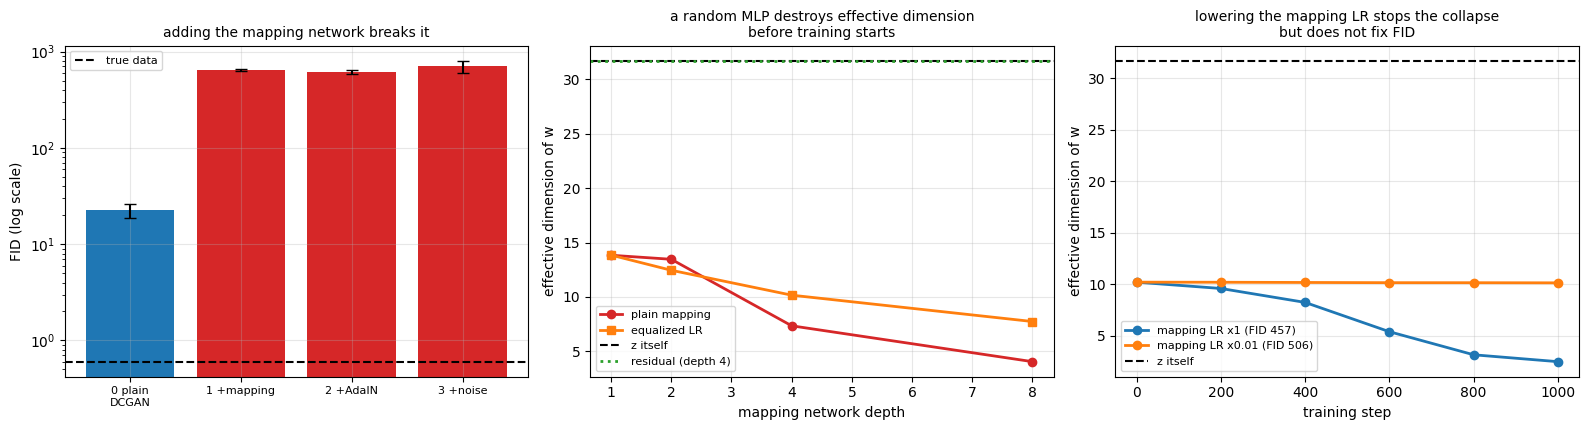

In [13]:
# ============================================================
# 図: 原因追跡のまとめ
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))

# (1) 部品を足すと FID がどうなるか
ax = axes[0]
names = ["0 plain\nDCGAN", "1 +mapping", "2 +AdaIN", "3 +noise"]
vals = [np.mean([m["fid"] for m in build_res[t]]) for t, _ in BUILD]
errs = [np.ptp([m["fid"] for m in build_res[t]]) / 2 for t, _ in BUILD]
ax.bar(range(4), vals, yerr=errs, capsize=4,
       color=["tab:blue", "tab:red", "tab:red", "tab:red"])
ax.axhline(base["test[5000:10000]"]["fid"], color="k", ls="--", lw=1.5,
           label="true data")
ax.set_yscale("log")
ax.set_xticks(range(4))
ax.set_xticklabels(names, fontsize=8)
ax.set_ylabel("FID (log scale)")
ax.set_title("adding the mapping network breaks it", fontsize=10)
ax.legend(fontsize=8)

# (2) 学習ゼロでの有効次元
ax = axes[1]
d_plain = [r for r in init_rows if r[1] is True]
ax.plot([r[0] for r in d_plain], [r[3] for r in d_plain], "o-", lw=2,
        color="tab:red", label="plain mapping")
ax.plot([r[0] for r in eq_rows], [r[2] for r in eq_rows], "s-", lw=2,
        color="tab:orange", label="equalized LR")
ax.axhline(eff_dim(z_probe), color="k", ls="--", lw=1.5, label="z itself")
ax.axhline(eff_dim(_w), color="tab:green", ls=":", lw=2, label="residual (depth 4)")
ax.set_xlabel("mapping network depth")
ax.set_ylabel("effective dimension of w")
ax.set_title("a random MLP destroys effective dimension\nbefore training starts",
             fontsize=10)
ax.legend(fontsize=8)

# (3) 学習中の有効次元の推移
ax = axes[2]
labels_en = {"equalized・mapping の学習率 1.0 倍": "mapping LR x1",
             "equalized・mapping の学習率 0.01 倍": "mapping LR x0.01"}
for tag, (hist, m) in track.items():
    ax.plot([h[0] for h in hist], [h[2] for h in hist], "o-", lw=2,
            label=f"{labels_en[tag]} (FID {m['fid']:.0f})")
ax.axhline(eff_dim(z_probe), color="k", ls="--", lw=1.5, label="z itself")
ax.set_xlabel("training step")
ax.set_ylabel("effective dimension of w")
ax.set_title("lowering the mapping LR stops the collapse\nbut does not fix FID",
             fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 読み取れること

#### 残差写像は初期状態を完全に保つ

| | w の std | 有効次元 |
|---|---|---|
| 残差写像の初期状態 | **1.0010** | **31.72** |
| $z$ そのもの | 1.0010 | 31.72 |

**小数点4桁まで一致**します。当然で、初期値では $w = z$ だからです。

#### 学習しても保たれ、FID が 24 分の1 になる

| 構成 | FID | シードごと | 有効次元 初→終 |
|---|---|---|---|
| 1 Mapping（素朴） | 643.175 | 662.4 / 623.9 | — |
| **残差写像 + BatchNorm** | **27.055** | 29.8 / 24.3 | 31.48 → 30.54 |
| **残差写像 + AdaIN** | **44.657** | **24.5 / 64.8** | 31.48 → 30.16 |
| 0 素の DCGAN | 22.425 | 26.1 / 18.7 | — |

643.2 → 27.1 で **24 分の1**。素の DCGAN（22.4）とほぼ同じ水準に戻りました。
有効次元も 31.48 → 30.54 でほぼ保たれます。

**ただし AdaIN はシード依存が残ります。** 24.5 と 64.8 で **2.6 倍**ばらつき、
BatchNorm の 24.3〜29.8 より明らかに不安定です。
「動くようになった」とは言えますが、「安定した」とは言えません。
以降の第6・7節は**この AdaIN モデルの seed 0 を 2000歩 学習したもの1つ**に基づきます。

#### 一般形 — 動いている系に深い写像を挿入するときは恒等写像から始める

本章の失敗は、GAN や StyleGAN に固有の話ではありません。

> ランダム初期化された深い写像は、**入力の情報を壊した状態から学習を始める**。
> 学習がそれを回復する保証はない。
> だから既に動いている系に写像を挿入するときは、
> **初期値で恒等写像になるようにする**（出力層をゼロ初期化した残差形）。

同じ型の設計が広く使われています。

| 手法 | 恒等写像から始める仕掛け |
|---|---|
| ResNet | 残差接続（ブロックの出力に入力を足す） |
| Transformer | 各サブ層の残差接続 |
| LoRA | $B$ をゼロ初期化するので初期値で $\Delta W = 0$ |
| ControlNet | ゼロ畳み込み（初期値で制御信号が効かない） |

本章で測ったのは、**これを守らないと何が起きるか**です
（有効次元 32 → 10.2、FID 22.4 → 643.2）。

<a id="probe"></a>
## 6. W 空間は Z 空間よりほどけているか

305 章は「Z 空間と W 空間の違い」を扱い、W 空間のほうが属性が整理されていると説明します。
**動くモデルが手に入ったので、測れます。**

### 測り方 — 線形プローブ

生成サンプルから因子（数字・色相）を読み取り、潜在ベクトルから
**線形回帰で**その因子を予測します。決定係数 $R^2$ と分類精度を見ます。

$$\hat{y} = A\,[\,v\,;1\,], \qquad v \in \{z, w\}$$

「ほどけている」なら、$w$ からのほうが線形に読み出せるはずです。

> **予測**: $w$ のほうが $R^2$・精度ともに高い。

ただし残差写像を使っているので、$w = z + \mathrm{MLP}(z)$ で $w \approx z$ になっていると
この比較は意味を持ちません。**残差の大きさも測って確認します**（これは第9節のつまずきです）。

In [14]:
# ============================================================
# 動くモデルを学習して、z と w の線形読み出しを比べる
# ============================================================

t0 = time.time()
M_OK, G_OK, D_OK, hist_ok = train_gan(steps=2000, seed=0, map_cls=MappingRes,
                                      norm="adain", track_every=2000)
S_OK, Z_OK, W_OK = sample_gan(M_OK, G_OK, n=5000)
m_ok = image_metrics(S_OK)
print(f"残差写像 + AdaIN を 2000歩: {time.time() - t0:.0f}s")
print(f"  FID {m_ok['fid']:.2f}  数字の偏り {m_ok['dig_dev']:.4f}  "
      f"色相の偏り {m_ok['hue_dev']:.4f}  確信度 {m_ok['conf']:.4f}")
print(f"  w の有効次元 {hist_ok[0][2]:.2f} → {hist_ok[-1][2]:.2f}")
print()

# 交絡の確認: w は z からどれだけ離れているか
with torch.no_grad():
    resid = M_OK.net(Z_OK)
cos = (Z_OK * W_OK).sum(-1) / (Z_OK.norm(dim=-1) * W_OK.norm(dim=-1))
print("交絡の確認（w が z に近すぎると比較が無意味になる）")
print(f"  ||z|| の平均 {float(Z_OK.norm(dim=-1).mean()):.4f}   "
      f"||MLP(z)|| の平均 {float(resid.norm(dim=-1).mean()):.4f}")
print(f"  残差の相対的な大きさ {float((resid.norm(dim=-1) / Z_OK.norm(dim=-1)).mean()):.4f}")
print(f"  z と w の余弦類似度 {float(cos.mean()):.4f}")
print()


def linear_probe(X, lab, n_cls):
    Y = F.one_hot(lab, n_cls).float()
    A = torch.cat([X, torch.ones(len(X), 1)], -1).numpy().astype(np.float64)
    Yn = Y.numpy().astype(np.float64)
    coef, _, _, _ = np.linalg.lstsq(A, Yn, rcond=None)
    pred = A @ coef
    r2 = 1 - ((Yn - pred) ** 2).sum() / ((Yn - Yn.mean(0)) ** 2).sum()
    return float(r2), float((pred.argmax(1) == lab.numpy()).mean())


with torch.no_grad():
    dig_lab = CLF(S_OK).argmax(1)
hue_lab = est_hue(S_OK)
print("線形プローブ（生成サンプル 5000）")
print(f"{'潜在空間':>10}{'数字 R2':>10}{'数字 精度':>11}{'色相 R2':>10}{'色相 精度':>11}")
print("-" * 52)
probe_res = {}
for tag, X in [("z", Z_OK), ("w", W_OK)]:
    r2d, accd = linear_probe(X, dig_lab, 10)
    r2h, acch = linear_probe(X, hue_lab, N_HUE)
    probe_res[tag] = (r2d, accd, r2h, acch)
    print(f"{tag:>10}{r2d:10.4f}{accd:11.4f}{r2h:10.4f}{acch:11.4f}")
print("-" * 52)
print(f"（当てずっぽうの精度は数字 0.100 / 色相 {1.0 / N_HUE:.3f}）")
print(f"差: 数字 R2 {abs(probe_res['w'][0] - probe_res['z'][0]):.4f}  "
      f"精度 {abs(probe_res['w'][1] - probe_res['z'][1]):.4f}")

残差写像 + AdaIN を 2000歩: 230s
  FID 18.40  数字の偏り 0.0436  色相の偏り 0.0598  確信度 0.8528
  w の有効次元 31.48 → 29.75

交絡の確認（w が z に近すぎると比較が無意味になる）
  ||z|| の平均 5.6176   ||MLP(z)|| の平均 3.8696
  残差の相対的な大きさ 0.6926
  z と w の余弦類似度 0.7962

線形プローブ（生成サンプル 5000）
      潜在空間     数字 R2      数字 精度     色相 R2      色相 精度
----------------------------------------------------
         z    0.2326     0.6158    0.2264     0.6858
         w    0.2334     0.6170    0.2272     0.6926
----------------------------------------------------
（当てずっぽうの精度は数字 0.100 / 色相 0.125）
差: 数字 R2 0.0008  精度 0.0012


### 読み取れること — 予測は外れた

#### まず交絡を確認する

残差写像では $w = z + \mathrm{MLP}(z)$ なので、残差が小さければ $w \approx z$ になり、
この比較は何も測っていないことになります。確認しました。

| | 値 |
|---|---|
| $\lVert z \rVert$ の平均 | 5.6176 |
| $\lVert \mathrm{MLP}(z) \rVert$ の平均 | 3.8696 |
| 残差の相対的な大きさ | **0.6926** |
| $z$ と $w$ の余弦類似度 | **0.7962** |

残差は $z$ の **69%** の大きさがあり、余弦類似度 0.80 です。
**$w$ は $z$ と実質的に別のベクトル**なので、比較は成立します。

#### 結果 — 区別がつかない

| 潜在空間 | 数字 $R^2$ | 数字 精度 | 色相 $R^2$ | 色相 精度 |
|---|---|---|---|---|
| $z$ | 0.2326 | 0.6158 | 0.2264 | 0.6858 |
| $w$ | 0.2334 | 0.6170 | 0.2272 | 0.6926 |
| 差 | **0.0008** | **0.0012** | 0.0008 | 0.0068 |

**小数点3桁まで同じ**です。$w$ のほうが線形に読み出せるという予測は外れました。

#### どう読むべきか

> 「W 空間のほうが属性がほどけている」は、**この設定では再現しません**。
> 否定したのは原典ではなく、**この規模で確かめられる範囲**です。

本章の条件を明示します。

- 解像度 16x16、注入点3つ、$w$ は 32 次元、学習 2000歩、**シード1つ**
- 原典は 1024x1024、18層、$w$ は 512 次元、数百万ステップ

$w$ の「ほどけ具合」は、Mapping Network が**学習を通じて獲得する**性質です。
2000歩では、$w$ は $z$ から離れてはいる（余弦 0.80）が、
**離れ方が属性の整理になっていない**と読むのが素直です。

305 章を読むときは「W 空間が優れている」を**前提として受け取らず**、
自分の規模で測ってから使うことです。

<a id="mixing"></a>
## 7. スタイル混合は層ごとに何を制御するか

StyleGAN の有名な図は、2つの潜在ベクトル $w_A, w_B$ を**層ごとに使い分ける**と
「粗い層が姿勢・顔の形、細かい層が髪の色・肌の質感」を決める、というものです。

本章のデータは因子が2つとも測れるので、**転移率として数値化できます**。

注入点は3つあります。

| 番号 | 場所 | 粗さ |
|---|---|---|
| 1 | 生成器の入力（4x4 を作る層） | 最も粗い |
| 2 | AdaIN（4x4） | 中間 |
| 3 | AdaIN（8x8） | 最も細かい |

注入点 $1..k$ を $w_A$、残りを $w_B$ にして、生成画像の数字と色相が
$A$ 側・$B$ 側のどちらと一致するかを数えます。

> **予測**: 粗い側（小さい $k$ でも $A$ になる注入点1）が**数字**を決め、
> 細かい側が**色相**を決める。つまり $k=1,2$ で
> 「数字は $A$ 由来・色相は $B$ 由来」になるはず。

In [15]:
# ============================================================
# スタイル混合 — 注入点 1..k を A、残りを B にする
# ============================================================

@torch.no_grad()
def style_mix(k, n=3000, seed=11):
    g = torch.Generator().manual_seed(seed)
    wA = M_OK(torch.randn(n, NZ, generator=g))
    wB = M_OK(torch.randn(n, NZ, generator=g))
    pick = lambda i: wA if i < k else wB
    was = G_OK.training
    G_OK.eval()
    xA = G_OK(wA[:, :, None, None], [wA, wA])
    xB = G_OK(wB[:, :, None, None], [wB, wB])
    xM = G_OK(pick(0)[:, :, None, None], [pick(1), pick(2)])
    G_OK.train(was)
    return xA, xB, xM


print("注入点 1..k を A、残りを B にする（k=0 は全部 B、k=3 は全部 A）")
print(f"{'k':>3}{'数字がAと一致':>14}{'数字がBと一致':>14}{'色相がAと一致':>14}{'色相がBと一致':>14}")
print("-" * 69)
mix_rows = []
for k in [0, 1, 2, 3]:
    xA, xB, xM = style_mix(k)
    with torch.no_grad():
        dM, dA, dB = CLF(xM).argmax(1), CLF(xA).argmax(1), CLF(xB).argmax(1)
    hM, hA, hB = est_hue(xM), est_hue(xA), est_hue(xB)
    r = (k, float((dM == dA).float().mean()), float((dM == dB).float().mean()),
         float((hM == hA).float().mean()), float((hM == hB).float().mean()))
    mix_rows.append(r)
    print(f"{r[0]:>3}{r[1]:14.4f}{r[2]:14.4f}{r[3]:14.4f}{r[4]:14.4f}")
print("-" * 69)
print()
print("A への偏り（A と一致 ÷ B と一致）。大きいほどその因子は粗い側で決まっている")
print(f"{'k':>3}{'数字の偏り':>12}{'色相の偏り':>12}")
print("-" * 27)
for k, dA, dB, hA, hB in mix_rows[1:3]:
    print(f"{k:>3}{dA / max(dB, 1e-6):12.2f}{hA / max(hB, 1e-6):12.2f}")
print("-" * 27)

注入点 1..k を A、残りを B にする（k=0 は全部 B、k=3 は全部 A）
  k       数字がAと一致       数字がBと一致       色相がAと一致       色相がBと一致
---------------------------------------------------------------------


  0        0.1103        1.0000        0.1357        1.0000


  1        0.7520        0.1193        0.5200        0.2363


  2        0.8663        0.1103        0.5710        0.2197


  3        1.0000        0.1103        1.0000        0.1357
---------------------------------------------------------------------

A への偏り（A と一致 ÷ B と一致）。大きいほどその因子は粗い側で決まっている
  k       数字の偏り       色相の偏り
---------------------------
  1        6.30        2.20
  2        7.85        2.60
---------------------------


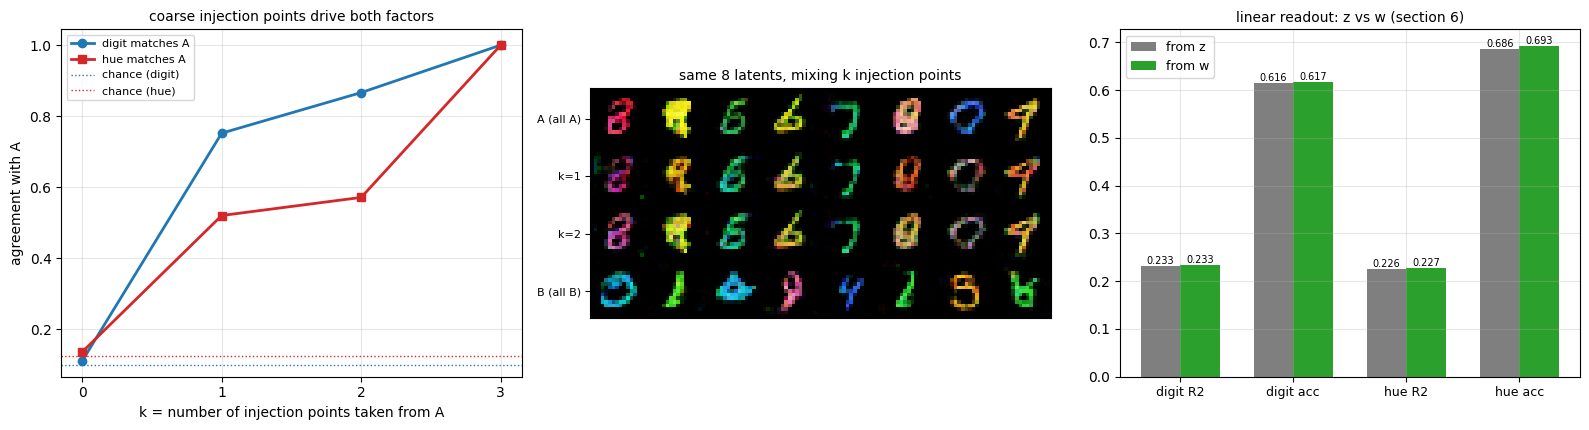

In [16]:
# ============================================================
# 図: スタイル混合
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))

ax = axes[0]
ks = [r[0] for r in mix_rows]
ax.plot(ks, [r[1] for r in mix_rows], "o-", lw=2, color="tab:blue",
        label="digit matches A")
ax.plot(ks, [r[3] for r in mix_rows], "s-", lw=2, color="tab:red",
        label="hue matches A")
ax.axhline(0.1, color="tab:blue", ls=":", lw=1, label="chance (digit)")
ax.axhline(1.0 / N_HUE, color="tab:red", ls=":", lw=1, label="chance (hue)")
ax.set_xlabel("k = number of injection points taken from A")
ax.set_ylabel("agreement with A")
ax.set_xticks(ks)
ax.set_title("coarse injection points drive both factors", fontsize=10)
ax.legend(fontsize=8)

# 画像で見る
xA, xB, xM1 = style_mix(1, n=8)
_, _, xM2 = style_mix(2, n=8)
rows = [("A (all A)", xA), ("k=1", xM1), ("k=2", xM2), ("B (all B)", xB)]
ax = axes[1]
grid = torch.cat([r[1][:8] for r in rows], 0)
g = grid.reshape(4, 8, 3, 16, 16).permute(0, 3, 1, 4, 2).reshape(64, 128, 3)
ax.imshow(((g + 1) / 2).clamp(0, 1).numpy())
ax.set_yticks([8, 24, 40, 56])
ax.set_yticklabels([r[0] for r in rows], fontsize=8)
ax.set_xticks([])
ax.grid(False)
ax.set_title("same 8 latents, mixing k injection points", fontsize=10)

# 線形プローブの比較
ax = axes[2]
labels = ["digit R2", "digit acc", "hue R2", "hue acc"]
xs = np.arange(4)
wd = 0.35
ax.bar(xs - wd / 2, probe_res["z"], wd, label="from z", color="tab:gray")
ax.bar(xs + wd / 2, probe_res["w"], wd, label="from w", color="tab:green")
ax.set_xticks(xs)
ax.set_xticklabels(labels, fontsize=9)
ax.set_title("linear readout: z vs w (section 6)", fontsize=10)
ax.legend(fontsize=9)
for i, (a, b) in enumerate(zip(probe_res["z"], probe_res["w"])):
    ax.text(i - wd / 2, a, f"{a:.3f}", ha="center", va="bottom", fontsize=7)
    ax.text(i + wd / 2, b, f"{b:.3f}", ha="center", va="bottom", fontsize=7)
plt.tight_layout()
plt.show()

### 読み取れること — 符号は当たり、大きさが足りない

| k | 数字が A と一致 | 数字が B と一致 | 色相が A と一致 | 色相が B と一致 |
|---|---|---|---|---|
| 0（全部 B） | 0.1103 | 1.0000 | 0.1357 | 1.0000 |
| **1**（入力だけ A） | **0.7520** | 0.1193 | **0.5200** | 0.2363 |
| **2**（入力 + 4x4 が A） | **0.8663** | 0.1103 | **0.5710** | 0.2197 |
| 3（全部 A） | 1.0000 | 0.1103 | 1.0000 | 0.1357 |

$k=0$ と $k=3$ が 1.0000 / 0.1103 の対称形になっているのは健全性の確認です
（0.1103 は10クラスの偶然 0.1 に近い）。

#### 粗い注入点が、形も見た目も決めてしまう

予測は「$k=1,2$ で**数字は A 由来・色相は B 由来**になる」でした。
実際は $k=1$ で**色相も 52% が A 由来**です。分離していません。

ただし偏りの比を見ると、**予測の向きは出ています**。

| k | 数字の A への偏り | 色相の A への偏り |
|---|---|---|
| 1 | **6.30** | **2.20** |
| 2 | **7.85** | **2.60** |

数字は A に 6.3 倍偏るのに対し、色相は 2.2 倍。
**色相のほうが後ろの層の影響を受けやすい**という傾向は確かにあります。

> 符号は当たりましたが、**大きさが足りません**。
> 192 の 1x1 可逆線形変換と同じ型の外れ方です
> （効く向きは正しいが、測定条件が小さすぎて効果が見えない）。

注入点が3つしかなく、解像度が 16x16 では、「粗い層」と「細かい層」の差が
$4\times4$ と $8\times8$ の違いしかありません。
原典は 18 層・$4^2$ から $1024^2$ までを覆うので、
分離が現れるのは**層の数と解像度の幅**によるのだと読めます。

<a id="progressive"></a>
## 8. 解像度カリキュラム（段階的成長の簡略版）

ProGAN の中心的な考えは**段階的成長**です。低解像度から学習を始め、
解像度を上げながら層を**追加**していきます。

### 本章で実装するもの・しないもの

| 原典 | 本章 |
|---|---|
| 低解像度の出力層（toRGB）を持ち、高解像度の層を**追加**する | **実装しない**（生成器は常に 16x16 を出す） |
| 判別器も対応して成長する | 8x8 用と 16x16 用の判別器を**別に持つ** |
| 新しい層を**フェードイン**する | フェードインは比較のために実装する |

つまり本章がやるのは「**解像度カリキュラム**」です。
低解像度の期間は生成器の出力を平均プーリングして 8x8 の判別器に渡します。

> **予測**: 低解像度で粗い構造を学んでから高解像度に移るので、
> 同じ総ステップ数なら直接学習より良くなるはず。
> フェードインを入れればさらに良くなるはず。

In [17]:
# ============================================================
# 解像度カリキュラムとフェードイン
# ============================================================

X_train8 = F.avg_pool2d(X_train, 2)


class Disc8(nn.Module):
    def __init__(self, ch=48):
        super().__init__()
        self.net = nn.Sequential(
            nn.Sequential(nn.Conv2d(3, ch * 2, 3, 1, 1, bias=False), nn.MaxPool2d(2)),
            nn.BatchNorm2d(ch * 2), nn.LeakyReLU(0.2),
            nn.Conv2d(ch * 2, 1, 4, 1, 0, bias=False))

    def forward(self, x):
        return self.net(x).flatten(1).squeeze(-1)


def train_curriculum(total=2000, frac8=0.0, fade=0, seed=0, batch=128, lr=2e-4, ch=48):
    # frac8 の割合だけ 8x8 で学習し、その後 fade ステップかけて 16x16 へ線形に移す
    torch.manual_seed(seed)
    M = MappingRes()
    G = Gen(ch=ch, norm="adain", nin=NW)
    D16, D8 = Disc(ch=ch), Disc8(ch=ch)
    og = torch.optim.Adam([{"params": list(G.parameters()), "lr": lr},
                           {"params": list(M.parameters()), "lr": lr}],
                          lr=lr, betas=(0.5, 0.999))
    od16 = torch.optim.Adam(D16.parameters(), lr=lr, betas=(0.5, 0.999))
    od8 = torch.optim.Adam(D8.parameters(), lr=lr, betas=(0.5, 0.999))
    n8 = int(total * frac8)
    for it in range(total):
        if it < n8:
            alpha = 0.0
        elif fade > 0 and it < n8 + fade:
            alpha = (it - n8) / fade
        else:
            alpha = 1.0
        xr16 = X_train[torch.randint(0, len(X_train), (batch,))]
        xr8 = X_train8[torch.randint(0, len(X_train8), (batch,))]
        with torch.no_grad():
            inp, ws, _, _ = latents(M, batch)
            xf16 = G(inp, ws)
            xf8 = F.avg_pool2d(xf16, 2)
        if alpha < 1.0:
            od8.zero_grad()
            ((1 - alpha) * (bce(D8(xr8), torch.ones(batch))
                            + bce(D8(xf8), torch.zeros(batch)))).backward()
            od8.step()
        if alpha > 0.0:
            od16.zero_grad()
            (alpha * (bce(D16(xr16), torch.ones(batch))
                      + bce(D16(xf16), torch.zeros(batch)))).backward()
            od16.step()
        inp, ws, _, _ = latents(M, batch)
        out = G(inp, ws)
        loss = 0.0
        if alpha > 0.0:
            loss = loss + alpha * bce(D16(out), torch.ones(batch))
        if alpha < 1.0:
            loss = loss + (1 - alpha) * bce(D8(F.avg_pool2d(out, 2)), torch.ones(batch))
        og.zero_grad()
        loss.backward()
        og.step()
    return M, G, D16


t0 = time.time()
curr_res, curr_G = {}, {}
print("総ステップ数はすべて 2000。2シード")
print(f"{'構成':<44}{'FID':>10}{'シードごと':>20}{'数字の偏り':>11}")
print("-" * 87)
for tag, kw in [("直接 16x16（カリキュラムなし）", dict(frac8=0.0, fade=0)),
                ("8x8 で 500歩 → 切り替え（フェードなし）", dict(frac8=0.25, fade=0)),
                ("8x8 で 500歩 → 600歩でフェードイン", dict(frac8=0.25, fade=600))]:
    ms = []
    for s in [0, 1]:
        M, G, D = train_curriculum(total=2000, seed=s, **kw)
        S, _, _ = sample_gan(M, G)
        if s == 0:
            curr_G[tag] = (M, G)
        ms.append(image_metrics(S))
    curr_res[tag] = ms
    f = lambda k: np.array([m[k] for m in ms])
    print(f"{tag:<44}{f('fid').mean():10.3f}{str(np.round(f('fid'), 1).tolist()):>20}"
          f"{f('dig_dev').mean():11.4f}")
print("-" * 87)
print(f"経過 {time.time() - t0:.0f}s")

総ステップ数はすべて 2000。2シード
構成                                                 FID               シードごと      数字の偏り
---------------------------------------------------------------------------------------


直接 16x16（カリキュラムなし）                              19.928        [19.1, 20.7]     0.0620


8x8 で 500歩 → 切り替え（フェードなし）                      268.164      [337.0, 199.3]     0.4556


8x8 で 500歩 → 600歩でフェードイン                       352.757      [301.3, 404.2]     0.4010
---------------------------------------------------------------------------------------
経過 1324s


In [18]:
# ============================================================
# 8x8 期だけのモデルを両解像度で評価する（機構の候補を調べる）
# ============================================================

REF8 = features(F.interpolate(F.avg_pool2d(X_test[:5000], 2),
                              scale_factor=2, mode="nearest"))

def fid_at_8(S):
    A = features(F.interpolate(F.avg_pool2d(S, 2), scale_factor=2, mode="nearest"))
    return fid_feature(A, REF8)


M8, G8, _ = train_curriculum(total=500, frac8=1.0, fade=0, seed=0)
S8, _, _ = sample_gan(M8, G8)
m8 = image_metrics(S8)
print("8x8 だけで 500歩 学習したモデル")
print(f"  8x8 での FID {fid_at_8(S8):8.2f}   16x16 での FID {m8['fid']:8.2f}   "
      f"市松指標 {m8['chk']:.5f}")
T = X_test[5000:10000]
print("対照: 真のデータ")
print(f"  8x8 での FID {fid_at_8(T):8.2f}   16x16 での FID {image_metrics(T)['fid']:8.2f}   "
      f"市松指標 {checkerboard(T):.5f}")
print()
print("候補の機構: 平均プーリングして評価すると、生成器は「平均すれば正しい」")
print("高周波のゴミを自由に作れる（最終層が拘束されない）。市松指標で見る")

/var/folders/6s/q776k1nj6rn9vjn979kn090w0000gn/T/ipykernel_54288/609723223.py:25: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  cc = sqrtm(C1 @ C2)


8x8 だけで 500歩 学習したモデル
  8x8 での FID   323.43   16x16 での FID   589.38   市松指標 0.08603
対照: 真のデータ


  8x8 での FID     0.33   16x16 での FID     0.60   市松指標 0.00208

候補の機構: 平均プーリングして評価すると、生成器は「平均すれば正しい」
高周波のゴミを自由に作れる（最終層が拘束されない）。市松指標で見る


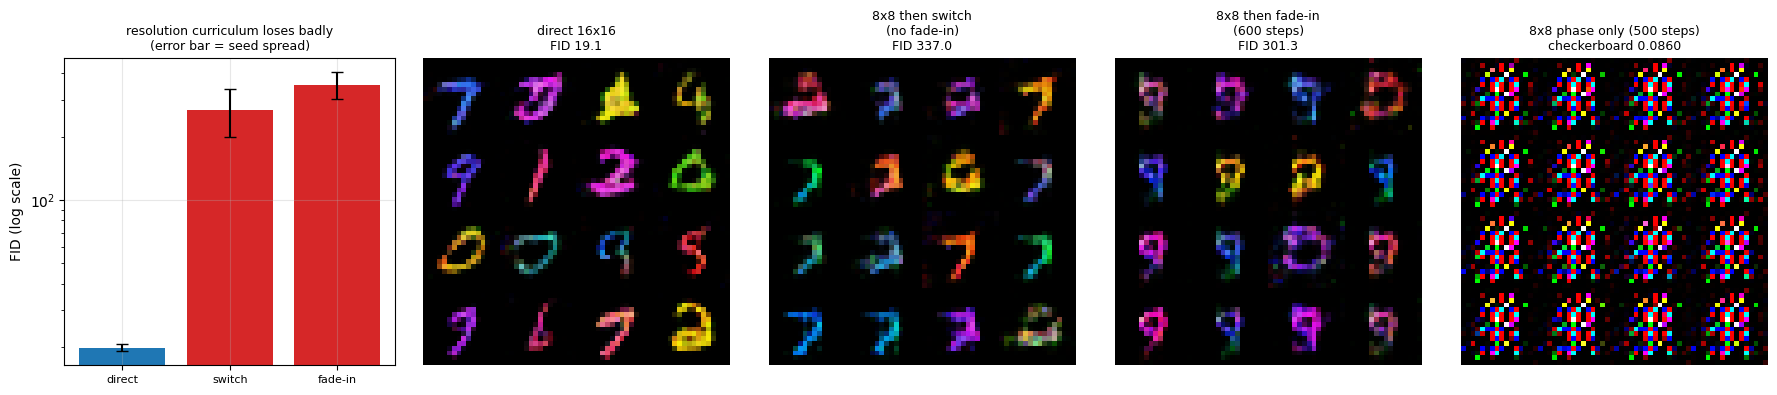

In [19]:
# ============================================================
# 図: 解像度カリキュラム
# ============================================================

curr_en = {"直接 16x16（カリキュラムなし）": "direct 16x16",
           "8x8 で 500歩 → 切り替え（フェードなし）": "8x8 then switch\n(no fade-in)",
           "8x8 で 500歩 → 600歩でフェードイン": "8x8 then fade-in\n(600 steps)"}

fig, axes = plt.subplots(1, 5, figsize=(18, 3.9))
tags = list(curr_res.keys())
ax = axes[0]
vals = [np.mean([m["fid"] for m in curr_res[t]]) for t in tags]
errs = [np.ptp([m["fid"] for m in curr_res[t]]) / 2 for t in tags]
ax.bar(range(3), vals, yerr=errs, capsize=4, color=["tab:blue", "tab:red", "tab:red"])
ax.set_yscale("log")
ax.set_xticks(range(3))
ax.set_xticklabels(["direct", "switch", "fade-in"], fontsize=8)
ax.set_ylabel("FID (log scale)")
ax.set_title("resolution curriculum loses badly\n(error bar = seed spread)", fontsize=9)
for ax, t in zip(axes[1:4], tags):
    M, G = curr_G[t]
    S, _, _ = sample_gan(M, G, n=16)
    show_grid(ax, S, f"{curr_en[t]}\nFID {curr_res[t][0]['fid']:.1f}")
S8s, _, _ = sample_gan(M8, G8, n=16)
show_grid(axes[4], S8s, f"8x8 phase only (500 steps)\ncheckerboard {m8['chk']:.4f}")
plt.tight_layout()
plt.show()

### 読み取れること — カリキュラムは効かず、フェードインも救わない

| 構成 | FID | シードごと | 数字の偏り |
|---|---|---|---|
| 直接 16x16（カリキュラムなし） | **19.928** | 19.1 / 20.7 | 0.0620 |
| 8x8 で 500歩 → 切り替え | 268.164 | **337.0 / 199.3** | 0.4556 |
| 8x8 で 500歩 → 600歩でフェードイン | 352.757 | 301.3 / 404.2 | 0.4010 |

予測は両方外れました。カリキュラムは直接学習の **13 倍**悪く、
**フェードインを入れるとさらに悪化**します（268 → 353）。
シード間のばらつきも大きい（337.0 対 199.3）。

#### 機構の候補を調べたが、特定できなかった

候補は「平均プーリングして 8x8 で評価すると、生成器は**平均すれば正しい**
高周波のゴミを自由に作れる（最終層が拘束されない）」でした。

| | 8x8 での FID | 16x16 での FID | 市松指標 |
|---|---|---|---|
| 8x8 だけで 500歩 | 323.43 | 589.38 | **0.08603** |
| 真のデータ | 0.33 | 0.60 | 0.00208 |

市松指標が真のデータの **41 倍**なのは候補と整合します。
**しかし 8x8 での FID も 323.43 と悪い**ので、
「低解像度では合っているのに高解像度で崩れる」が成立していません。
500歩では 8x8 自体がまだ学習不足です。

> **機構は特定できていません。** 候補と整合する証拠（市松 41 倍）はありますが、
> 前提（8x8 では合っている）が確認できていないので、原因とは呼べません。

#### ただし本章の実装が原典と違う点は明確

| 原典（ProGAN） | 本章 |
|---|---|
| 解像度ごとに出力層（toRGB）を持ち、**層を追加**する | 生成器は常に 16x16 を出し、**層は追加しない** |
| 判別器も成長し、入力層が追加される | 8x8 用と 16x16 用の判別器を**別に持つ** |

本章が測ったのは「解像度カリキュラム」であって「段階的成長」ではありません。
**段階的成長の効果については、本章は何も言えません。**
層の追加を実装した検証は今後の課題です。

<a id="pitfalls"></a>
## 9. 実装でつまずいた点

### (1) 「原因」と呼ぶのが早すぎた（2回）

**1回目**: 第4節で尺度の崩壊（$z$ の 8.2%）を見つけたとき、
「equalized learning rate が Mapping Network の必要条件だ」と書くつもりでした。
ところが実際に学習すると FID 643 → 457 / 245 で、素の DCGAN（22.4）には届きません。
**必要条件かもしれないが十分条件ではない**、が正しい記述です。

**2回目**: 学習中の有効次元の崩壊（10.20 → 2.48）を見つけたとき、
これが原因だと思いました。ところが学習率を 0.01 倍にして
崩壊を止めても（10.14）FID は 506 のままでした。
**崩壊は症状**で、原因は開始時点の有効次元の低さでした。

183 で「仮説を棄却するときも測り方を疑う」、
184 で「順位を読むときも測り方を疑う」と書きましたが、
ここで必要だったのは **「支持された仮説も、十分条件かを確かめる」**です。
機構が見えると、そこで止めたくなります。

### (2) 修正が、測りたかったものを壊しかけた

第6節で $z$ と $w$ を比べるのに、残差写像 $w = z + \mathrm{MLP}(z)$ を使いました。
残差が小さければ $w \approx z$ で、比較は何も測っていないことになります。

**気づいて測りました**。残差の相対的な大きさ 0.6926、余弦類似度 0.7962。
$w$ は $z$ と別物だったので比較は成立しました。

> 学習を成立させるための修正が、**測定対象を変えてしまう**ことがあります。
> 「動くようになった」と「測りたいものがまだ測れる」は別の確認です。

### (3) 失敗の基準を先に測っておくと読みやすい

FID 643 と言われても、それが「悪い」のか「壊れている」のか分かりません。
**一様ノイズ画像の FID を測っておくと 613.7** で、
643 がノイズと同程度＝完全な崩壊だと即断できました。

同じ理由で、真のデータ同士の FID（0.60）も測っています。
**上端と下端の両方**を押さえると、途中の数値が解釈できます。

### (4) 2シードでは足りない場面がある

残差写像 + AdaIN は 24.5 と 64.8 で **2.6 倍**ばらつきました。
2シードでは平均 44.7 の信頼区間が分かりません。
第6・7節は seed 0 の1モデルに依存しているので、
**結論の強さは「1つの学習結果での観察」までです**。

計算コストとの兼ね合いで本章はここで止めましたが、
$z$ と $w$ の差が 0.0008 という小さな値を扱う第6節は、
本来は複数シードで確かめるべきところです。

<a id="summary"></a>
## 10. まとめとチートシート

### 測った数値

| 問い | 答え | 根拠 |
|---|---|---|
| 素の DCGAN に Mapping Network を足すとどうなるか | **崩壊する**。FID 22.4 → 643.2（一様ノイズ画像は 613.7） | BatchNorm も入力も判別器も変えていない |
| AdaIN が原因か | **違う**。AdaIN を足す前の段で既に壊れている（608.8 と 643.2 はシードの範囲が重なる） | 部品を1つずつ足したから分かった |
| 素朴な Mapping は何をするか | 学習ゼロで $w$ の尺度を $z$ の **8.2%** に、有効次元を 32 → **7.35** にする | depth 8 では 4.05 |
| PixelNorm は効くか | **ほぼ無効**（0.24321 対 0.24327）。標準正規入力に対して恒等写像に近い | |
| equalized learning rate は尺度を直すか | **直す**（0.082 → 0.986）。FID も 1.4〜2.6 倍改善するが **22.4 には届かない** | 457.3 / 244.8 |
| 学習中に何が起きているか | 尺度は潰れず、**有効次元が単調に崩壊**（10.20 → 2.48） | 200歩ごとに追跡 |
| mapping の学習率を 0.01 倍にすると | **崩壊は止まる**（10.14）が FID は 506.3 のまま → **崩壊は症状** | |
| 本当の原因は | **開始時点の有効次元の低さ**。学習は回復しない | |
| 直し方 | **残差写像** $w = z + \mathrm{MLP}(z)$（出力層をゼロ初期化）。FID 643.2 → **27.1** | 有効次元 31.48 → 30.54 |
| W 空間は Z 空間よりほどけているか | **この設定では差が無い**（数字 $R^2$ 0.2326 対 0.2334、精度の差 0.0012） | 交絡も確認済み（余弦類似度 0.7962） |
| スタイル混合は層ごとに分離するか | **分離しない**。$k=1$ で色相も 52% が A 由来。ただし偏りの比は数字 6.30 対 色相 2.20 で**向きは正しい** | 注入点3つ・16x16 では足りない |
| 解像度カリキュラムは効くか | **効かない**（19.9 → 268.2）。フェードインを入れると更に悪化（352.8） | 機構は特定できていない |

### 設計の指針

| やること | 理由 |
|---|---|
| 動いている系に深い写像を挿入するときは**恒等写像から始める** | ランダム初期化は入力の有効次元を壊す（32 → 10.2） |
| 部品は**1つずつ**足す | まとめて足すと、どれが壊したか分からない |
| **失敗の基準**を先に測る（一様ノイズなど） | 643 が「悪い」のか「崩壊」かを判定できる |
| 「原因が分かった」と思ったら**十分条件か確かめる** | 本章では2回、機構が正しくても直らなかった |
| 学習を直す修正が**測定対象を変えていないか**確認する | 残差写像で $w \approx z$ になると第6節が無意味になる |
| 潜在空間は**有効次元**で見る（尺度だけ見ない） | 尺度は保たれたまま次元だけ崩壊する |

### 他の章との接続

| 章 | 本章との関係 |
|---|---|
| **181** | 経験則を外す / 本章は足す。評価指標の作り方と「失敗の基準を測る」を引き継いだ |
| **182** | シードの範囲で判断する規律。本章では AdaIN の 2.6 倍のばらつきがそれで見えた |
| **184** | 「損失が見ない自由度は任意になる」。$w$ の有効次元は損失に現れないので崩壊する |
| **305** | 「Z 空間と W 空間の違い」を本章で測った。差は検出できなかった |
| **307 / 308** | 属性方向の発見（InterFaceGAN / GANSpace）。本章の結果は、
その前提である「W 空間の整理」が規模に依存することを示す |
| **186 VQ-GAN** | 離散表現の学習にも「コードブックの有効次元が崩壊する」（コードブック崩壊）という同じ型の問題がある |

### 次章へ

186（VQ-GAN）では潜在を**離散トークン**にします。
本章で測った「損失が見ない自由度は崩壊する」は、
VQ-VAE のコードブック崩壊（使われないコードが増える）とまったく同じ型の問題です。

<a id="quiz"></a>
## 11. 自己評価クイズ

1. 素の DCGAN（FID 22.4）に Mapping Network を足したら FID 643.2 になった。
   「AdaIN が悪い」と結論してよいか。本章の数値で答えよ。

2. FID 643.2 が「悪い」のか「崩壊」なのかを判定するには、何を測っておくべきか。

3. 学習を1歩もしていない Mapping Network を通すと、$w$ の有効次元が 32 → 7.35 になった。
   PixelNorm を入れても 7.41 でほとんど変わらなかった。なぜか。

4. equalized learning rate は $w$ の尺度を 0.082 → 0.986 に戻した。
   それでも FID は 457 だった。この事実から何が言えるか。

5. mapping の学習率を 0.01 倍にすると、有効次元の崩壊（10.20 → 2.48）が止まった
   （10.20 → 10.14）。しかし FID は 506 だった。崩壊は原因か。

6. 残差写像 $w = z + \mathrm{MLP}(z)$ で出力層をゼロ初期化すると FID 27.1 になった。
   この設計と同じ型の仕掛けを使っている手法を3つ挙げよ。

7. 第6節で $z$ と $w$ を比べる前に、残差の大きさを測った。なぜ必要だったか。

8. $z$ と $w$ の線形プローブの差が $R^2$ で 0.0008 だった。
   「W 空間は Z 空間と同じ」と書いてよいか。どう書くべきか。

9. スタイル混合で $k=1$ のとき、数字は A に 6.30 倍、色相は A に 2.20 倍偏った。
   StyleGAN の「粗い層が形、細かい層が見た目」は再現したと言えるか。

10. 解像度カリキュラムが直接学習（19.9）に対し 268.2 だった。
    フェードインを入れたら 352.8 でさらに悪化した。
    この結果から「段階的成長は効かない」と言えるか。

---

### 解答の指針

1. **言えない。** AdaIN を足す前の段（1 + Mapping、643.2）で既に壊れており、
   AdaIN を足した 2（608.8）とはシードの範囲が重なる（578.6-638.9 対 623.9-662.4）。
   部品を1つずつ足したからこの切り分けができた。

2. **失敗の上端**（一様ノイズ画像 613.7）と**成功の下端**（真のデータ同士 0.60）。
   643.2 がノイズと同程度だと分かれば、「悪化」ではなく「崩壊」と判定できる。

3. PixelNorm は $x / \sqrt{\mathbb{E}[x_i^2]}$ で、入力が標準正規なら
   $\mathbb{E}[z_i^2] \approx 1$ なのでほぼ恒等写像になる。
   有効次元を落としているのは各 Linear 層の初期化であって、入力の尺度ではない。

4. 尺度の崩壊は**原因の一部にすぎない**。
   「equalized learning rate が必要条件」とは言えるかもしれないが、
   **十分条件ではない**。機構が見えても、直るかは別に確かめる。

5. **原因ではない（症状）。** 崩壊を止めても FID が直らないので、
   崩壊は結果の側にある。共通して残る事実は「開始時点の有効次元が 10.20」で、
   学習はそれを回復しない。

6. ResNet の残差接続、Transformer の各サブ層の残差接続、
   LoRA（$B$ のゼロ初期化で $\Delta W = 0$）、ControlNet のゼロ畳み込み。
   いずれも「初期値で恒等写像」にして、既に動いている系を壊さない。

7. 残差写像では $w = z + \mathrm{MLP}(z)$ なので、残差が小さいと $w \approx z$ になり、
   比較が何も測っていないことになる。測った結果は相対的な大きさ 0.6926、
   余弦類似度 0.7962 で、$w$ は $z$ と別物だったので比較は成立した。

8. 書いてはいけない。書くべきは「**この設定では差を検出できなかった**」。
   条件（16x16、$w$ は 32 次元、2000歩、**シード1つ**）を明記する。
   原典は 1024x1024・512 次元・18層で、規模が3桁違う。

9. **再現したとは言えない。** $k=1$ で色相も 52% が A 由来なので分離していない。
   ただし偏りの比（数字 6.30 対 色相 2.20）は予測の**向き**と一致する。
   「符号は当たったが大きさが足りない」型の結果で、
   注入点3つ・16x16 では層の粗さの差が足りないと読む。

10. **言えない。** 本章が実装したのは解像度カリキュラムであって段階的成長ではない。
    原典は解像度ごとに出力層を持ち**層を追加**するが、本章は層を追加せず
    常に 16x16 を出して平均プーリングしている。
    段階的成長の効果について本章は何も言えない。
    加えて、カリキュラムが悪化する機構自体も特定できていない
    （市松指標 41 倍は候補と整合するが、8x8 での FID も 323 で前提が成立しない）。